In [1]:
!pip install -q transformers langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 13.4 MB/s eta 0:00:0000:0100:01
  Preparing metadata (setup.py) ... done


In [2]:
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch.nn.functional as F
from tqdm import tqdm

In [3]:
import os

# List all datasets mounted under /kaggle/input
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(f"Folder: {dirname}")
    for filename in filenames:
        print(f"  File: {filename}")


Folder: /kaggle/input
Folder: /kaggle/input/review-full
  File: reviews.csv


In [4]:
#import the reviews
df = pd.read_csv("/kaggle/input/review-full/reviews.csv")

In [5]:
df = df.dropna(subset=["comments"])
df.head(15)

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,68398,2894700,2012-11-16,3534183,Laura,I enjoyed my stay very much! Spend approx 6 we...
1,68398,13416072,2014-05-27,12750484,Maggie,I ended up staying in Studio B. Apartment is c...
2,68398,22427468,2014-11-06,21131563,Vincent,"Lisa est très efficace, le logement est foncti..."
3,68398,48514756,2015-09-27,31102107,Romney,I arrived a little early but Vincent valiantly...
4,68398,58001272,2015-12-31,44450239,Sheila,Our host made us feel very welcomed and was al...
5,68398,117113566,2016-12-04,26120062,Kathryn,"Awesome location. Cute, clean and stocked wit..."
6,68398,431471395,2019-04-01,126013182,Ha Neul,"Fair rate, clean room, comfortable bed, nice l..."
7,68398,984403762941767191,2023-09-20,470164880,Gita,Very nice!
8,68398,1013442366666899296,2023-10-30,209002431,Jan,"Wonderful stay! Can recommend, I felt right at..."
9,68398,1042475865706152726,2023-12-09,99035052,Amy,The location of this unit is at the popular Ea...


In [6]:
reviews = df["comments"]
reviews.head(15)
reviews.shape

(203800,)

In [7]:
#define the model
model_name = "nlptown/bert-base-multilingual-uncased-sentiment"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

model = model.to("cuda")

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

2025-07-13 14:24:21.971241: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1752416662.151610      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1752416662.208482      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


model.safetensors:   0%|          | 0.00/669M [00:00<?, ?B/s]

In [8]:
#Define sentiment scoring function

def get_sentiment_score(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True).to("cuda")
    with torch.no_grad(): #not in training model
        outputs = model(**inputs) #unpack inputs (a dictionary) and run the input text through the model
    probs = F.softmax(outputs.logits, dim=1)
    scores = torch.arange(1,6).float().to("cuda")
    weighted_avg = torch.sum(probs * scores, dim=1).item()
    return weighted_avg

    
        

In [9]:
tqdm.pandas()
df["sentiment score"] = df["comments"].progress_apply(get_sentiment_score)

100%|██████████| 203800/203800 [28:06<00:00, 120.86it/s]


In [10]:
df["score_1_to_10"] = df["sentiment score"] * 2

In [11]:
df.to_csv("reviews_with_sentiment.csv", index=False)


In [12]:
df.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments,sentiment score,score_1_to_10
0,68398,2894700,2012-11-16,3534183,Laura,I enjoyed my stay very much! Spend approx 6 we...,4.700985,9.401971
1,68398,13416072,2014-05-27,12750484,Maggie,I ended up staying in Studio B. Apartment is c...,3.417348,6.834696
2,68398,22427468,2014-11-06,21131563,Vincent,"Lisa est très efficace, le logement est foncti...",4.383955,8.767909
3,68398,48514756,2015-09-27,31102107,Romney,I arrived a little early but Vincent valiantly...,4.106307,8.212613
4,68398,58001272,2015-12-31,44450239,Sheila,Our host made us feel very welcomed and was al...,4.655263,9.310527


In [13]:
df_trimmed = df[["comments", "sentiment score", "score_1_to_10"]]

In [14]:
df_trimmed.head(15)

,comments,sentiment score,score_1_to_10
0,I enjoyed my stay very much! Spend approx 6 we...,4.700985,9.401971
1,I ended up staying in Studio B. Apartment is c...,3.417348,6.834696
2,"Lisa est très efficace, le logement est foncti...",4.383955,8.767909
3,I arrived a little early but Vincent valiantly...,4.106307,8.212613
4,Our host made us feel very welcomed and was al...,4.655263,9.310527
5,"Awesome location. Cute, clean and stocked wit...",4.837623,9.675246
6,"Fair rate, clean room, comfortable bed, nice l...",4.158469,8.316937
7,Very nice!,4.691565,9.383129
8,"Wonderful stay! Can recommend, I felt right at...",4.721631,9.443262
9,The location of this unit is at the popular Ea...,4.519812,9.039623


In [15]:
raw_score = df["sentiment score"]
adjusted_scored = df["score_1_to_10"]

In [16]:
df_trimmed[df["sentiment score"] < 2]

,comments,sentiment score,score_1_to_10
86,The host canceled my reservation the day befor...,1.524842,3.049684
121,"Advertised at ""2 bedrooms"", in reality only on...",1.672124,3.344249
272,Awful moth ball smell that burned our lungs. E...,1.312493,2.624987
500,"The two nights stay was awful, the worst thing...",1.303672,2.607345
531,BED BUGS or FLEAS\r<br/>\r<br/>We stayed there...,1.932704,3.865408
...,...,...,...
203650,"Frankly, we are very disappointed. The room is...",1.935605,3.871210
203654,整體來說以這個價錢是可以考慮的，但最不能接受就是床墊，一坐下去感覺要爛掉，嚴重影響睡眠質素。...,1.913539,3.827078
203681,"저렴한 가격에, 높은 숙소 퀄리티, 괜찮은 위치 흠잡을것이 없었습니다.",1.931930,3.863860
203769,這樣的價格沒有提供最基本吹風機，偏貴,1.972274,3.944548


In [17]:
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0

def detect_language(text):
    try:
        return detect(text)
    except:
        return "unknown"

In [18]:
df["language"] = df["comments"].progress_apply(detect_language)

100%|██████████| 203800/203800 [07:16<00:00, 466.72it/s]


In [19]:
df_trimmed = df[["listing_id","comments", "sentiment score", "score_1_to_10", "language"]]

In [20]:
df_trimmed

,listing_id,comments,sentiment score,score_1_to_10,language
0,68398,I enjoyed my stay very much! Spend approx 6 we...,4.700985,9.401971,en
1,68398,I ended up staying in Studio B. Apartment is c...,3.417348,6.834696,en
2,68398,"Lisa est très efficace, le logement est foncti...",4.383955,8.767909,fr
3,68398,I arrived a little early but Vincent valiantly...,4.106307,8.212613,en
4,68398,Our host made us feel very welcomed and was al...,4.655263,9.310527,en
...,...,...,...,...,...
203844,1380086727371793846,Great Airbnb near Technology Building MRT Stat...,4.826542,9.653085,en
203845,1380086727371793846,This Airbnb near Technology Building MRT Stati...,4.903874,9.807749,en
203846,1383071330903319991,安靜、乾淨、離捷運很近，五星推薦的公寓,4.515473,9.030947,ko
203847,1383769652913432484,location was perfect. Busy night market had ...,4.651124,9.302247,en


In [21]:
language_counts = df["language"].value_counts()
language_counts.index

Index(['en', 'ko', 'zh-tw', 'zh-cn', 'ja', 'fr', 'so', 'unknown', 'de', 'ro',
       'th', 'af', 'vi', 'es', 'pl', 'cs', 'it', 'ca', 'nl', 'no', 'cy', 'id',
       'tl', 'hr', 'da', 'pt', 'sv', 'sw', 'sk', 'et', 'fi', 'tr', 'he', 'hu',
       'lt', 'sl', 'ru', 'sq', 'lv', 'ar', 'mk', 'hi', 'el', 'ml'],
      dtype='object', name='language')

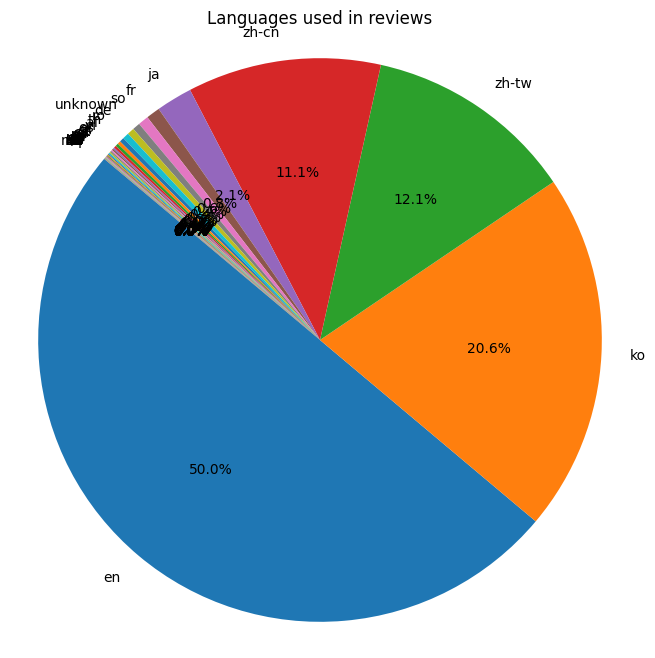

In [22]:
plt.figure(figsize=(8, 8))
plt.pie(language_counts.values,
        labels=language_counts.index,
        autopct='%1.1f%%',
        startangle=140)
plt.title("Languages used in reviews")
plt.axis('equal')
plt.show()

In [23]:
!pip install plotly

import plotly.express as px

fig = px.pie(df, names="language", title="Languages Used in Reviews")
fig.show()


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [24]:
df_trimmed

,listing_id,comments,sentiment score,score_1_to_10,language
0,68398,I enjoyed my stay very much! Spend approx 6 we...,4.700985,9.401971,en
1,68398,I ended up staying in Studio B. Apartment is c...,3.417348,6.834696,en
2,68398,"Lisa est très efficace, le logement est foncti...",4.383955,8.767909,fr
3,68398,I arrived a little early but Vincent valiantly...,4.106307,8.212613,en
4,68398,Our host made us feel very welcomed and was al...,4.655263,9.310527,en
...,...,...,...,...,...
203844,1380086727371793846,Great Airbnb near Technology Building MRT Stat...,4.826542,9.653085,en
203845,1380086727371793846,This Airbnb near Technology Building MRT Stati...,4.903874,9.807749,en
203846,1383071330903319991,安靜、乾淨、離捷運很近，五星推薦的公寓,4.515473,9.030947,ko
203847,1383769652913432484,location was perfect. Busy night market had ...,4.651124,9.302247,en


In [26]:
df_trimmed.to_csv("review_sentiment_analysis.csv", index=False)